#**Tracking Early Engagement to Predict Learner Dropout in Online Course**


# Tracking Early Engagement to Predict Learner Dropout in Online Courses
**WesOnline Mentorship, Advanced Data Analysis and Visualization | Project 1 (Monitoring and Evaluation)**

## Problem Statement
Learners withdraw from online courses before finishing, and project coordinators often find out too late to help.

## Main question
Can engagement and registration data from the first four weeks identify learners at risk of dropping out early enough for a project coordinator to intervene?

## Dataset
Open University Learning Analytics Dataset (OULAD): 32,593 learner-module records. It is UK higher-education data used as a proxy for a training programme. **Download link:** https://figshare.com/articles/OULAD_Open_University_Learning_Analytics_Dataset/5081998.

## Objectives
1. What are the baseline dropout and pass rates, and which modules and learner groups are affected most?
2. At what points in the course do learners withdraw?
3. Which early signals are linked to later withdrawal?
4. Can the early signals be combined into a risk flag at week 4, and how accurately does it identify learners who later withdraw?
5. How can the findings be presented so a project coordinator knows which learners to contact first?

In [2]:
import os
path = "/content/drive/MyDrive/M&E PROJECT"
print(os.path.exists(path))
print(os.listdir(path))

True
['studentAssessment.csv', 'studentVle.csv', 'assessments.csv', 'courses.csv', 'studentInfo.csv', 'studentRegistration.csv', 'vle.csv', 'weekly_clicks.csv', 'chart_weekly_clicks.png', 'chart_module.png', 'chart_timing.png', 'chart_funnel.png', 'chart_engagement.png', 'learner_risk_scores.csv', 'chart_deciles.png']


In [3]:
import os
import pandas as pd

courses        = pd.read_csv(os.path.join(path, "courses.csv"))
assessments    = pd.read_csv(os.path.join(path, "assessments.csv"))
vle            = pd.read_csv(os.path.join(path, "vle.csv"))
student_info   = pd.read_csv(os.path.join(path, "studentInfo.csv"))
student_reg    = pd.read_csv(os.path.join(path, "studentRegistration.csv"))
student_assess = pd.read_csv(os.path.join(path, "studentAssessment.csv"))

In [4]:
# The first 5 rows of the main learner table
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [5]:
# Outcome counts: how many learners passed, failed, withdrew, etc.
student_info["final_result"].value_counts()

,count
final_result,
Pass,12361
Withdrawn,10156
Fail,7052
Distinction,3024


In [6]:
#Percentages: how many learners passed, failed, withdrew, etc.
(student_info["final_result"].value_counts(normalize=True) * 100).round(1)

,proportion
final_result,
Pass,37.9
Withdrawn,31.2
Fail,21.6
Distinction,9.3


In [7]:
# Missing values per column
# Note: blanks in date_unregistration are expected (learners who never withdrew)
student_info.isna().sum()

,0
code_module,0
code_presentation,0
id_student,0
gender,0
region,0
highest_education,0
imd_band,1111
age_band,0
num_of_prev_attempts,0
studied_credits,0


In [8]:
# Missing values in the registration table.
student_reg.isna().sum()

,0
code_module,0
code_presentation,0
id_student,0
date_registration,45
date_unregistration,22521


In [9]:
# Duplicate check: one row should equal one student in one course presentation
keys = ["code_module", "code_presentation", "id_student"]
print(student_info.duplicated(subset=keys).sum())
print(student_reg.duplicated(subset=keys).sum())

0
0


In [10]:
for name, tbl in {"courses": courses, "assessments": assessments, "vle": vle,
                  "studentInfo": student_info, "studentRegistration": student_reg,
                  "studentAssessment": student_assess}.items():
    print(name, tbl.shape)

courses (22, 3)
assessments (206, 6)
vle (6364, 6)
studentInfo (32593, 12)
studentRegistration (32593, 5)
studentAssessment (173912, 5)


In [11]:
# Dropout column: 1 = withdrew, 0 = stayed to the end
student_info["dropout"] = (student_info["final_result"] == "Withdrawn").astype(int)

print(student_info["dropout"].value_counts())
print("Dropout rate:", round(student_info["dropout"].mean() * 100, 1), "%")

dropout
0    22437
1    10156
Name: count, dtype: int64
Dropout rate: 31.2 %


**Out of 32,593 learner-module records, 10,156 (31.2%) withdrew before the end of the course. This is the baseline dropout rate for the project.**

**The at-risk flag is made at week 4 (day 2)**
. Learners who withdrew before day 28 are excluded, because a warning would come too late for them.

In [12]:
keys = ["code_module", "code_presentation", "id_student"]

base = student_info.merge(
    student_reg[keys + ["date_registration", "date_unregistration"]],
    on=keys, how="left"
)
print(base.shape)

(32593, 15)


In [13]:
import os
import matplotlib.pyplot as plt

NAVY, TERRA, EMER = "#1E3A8A", "#EA580C", "#047857"
INK, BODY, GRID = "#0F172A", "#475569", "#CBD5E1"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "text.color": INK, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.yaxis.grid(True, color=GRID, linewidth=0.6); ax.set_axisbelow(True)

def bar(series, title, xlabel="", ylabel="Dropout rate (%)", colors=None, fname=None):
    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    ax.bar(series.index.astype(str), series.values, color=colors or NAVY, width=0.6)
    style(ax, title, xlabel, ylabel)
    ax.set_ylim(0, series.max() * 1.18)
    for i, v in enumerate(series.values):
        ax.text(i, v + series.max() * 0.02, f"{v:.1f}%", ha="center", fontweight="bold")
    plt.tight_layout()
    if fname: fig.savefig(os.path.join(path, fname), dpi=200)
    plt.show()

# **Objective 1:** What are the baseline dropout and pass rates, and which modules and learner groups are affected most?

**Baseline indicators.** Dropout rate and pass rate for all 32,593 learner-module records, broken down by module, region, gender, age band, and prior education. Dropout = Withdrawn. Pass = Pass or Distinction. Learners who failed stayed to the end, so they are neither dropouts nor passes.

In [14]:
# Pass = Pass or Distinction
base["passed"] = base["final_result"].isin(["Pass", "Distinction"]).astype(int)

def baseline_table(col):
    """Learners, dropout rate (%) and pass rate (%) for each group in one column."""
    t = (base.groupby(col, observed=True)
             .agg(learners=("dropout", "size"),
                  dropout_rate=("dropout", "mean"),
                  pass_rate=("passed", "mean")))
    t["dropout_rate"] = (t["dropout_rate"] * 100).round(1)
    t["pass_rate"] = (t["pass_rate"] * 100).round(1)
    return t.sort_values("dropout_rate", ascending=False)

# Overall figures first
print("All learners:", len(base))
print("Dropout rate:", round(base["dropout"].mean() * 100, 1), "%")
print("Pass rate:   ", round(base["passed"].mean() * 100, 1), "%")

# One table for each breakdown
for col in ["code_module", "region", "gender", "age_band", "highest_education"]:
    print(f"\n--- by {col} ---")
    print(baseline_table(col))

All learners: 32593
Dropout rate: 31.2 %
Pass rate:    47.2 %

--- by code_module ---
             learners  dropout_rate  pass_rate
code_module                                   
CCC              4434          44.5       37.8
DDD              6272          35.9       41.6
FFF              7762          31.0       47.0
BBB              7909          30.2       47.5
EEE              2934          24.6       56.2
AAA               748          16.8       71.0
GGG              2534          11.5       59.7

--- by region ---
                      learners  dropout_rate  pass_rate
region                                                 
North Western Region      2906          35.6       40.2
West Midlands Region      2582          35.4       43.3
East Midlands Region      2365          34.8       45.7
London Region             3216          34.5       42.4
Yorkshire Region          2006          32.8       44.9
North Region              1823          31.5       50.5
South West Region       

**Finding:** Of 32,593 learner-module records, 31.2% withdrew and 47.2% passed. Dropout varies most by module (CCC 44.5% to GGG 11.5%), then by prior education (42.9% for no formal qualifications down to 23.6% for postgraduates) and region (35.6% in the North Western Region to 23.1% in Ireland). Gender differences are small (31.7% male, 30.5% female). The groups overlap, and some are small (55+, no formal qualifications, postgraduate), so these are descriptive differences and not causes. The results show where support is most needed.

# **Objectivw 2:** At what points in the course do learners withdraw?

**Objective 2: when do learners withdraw?** Locate the drop-off points. Shows in which week of the course learners withdraw, how many of the 32,593 records have unregistered by key days, and how this differs by module. date_unregistration is the day relative to the course start (0 = start day).

Withdrawn learners: 10156
With a recorded unregistration date: 10063
      withdrawals  share_%  cumulative_%
week                                    
0            2676     26.6          26.6
1             713      7.1          33.7
2            1068     10.6          44.3
3             215      2.1          46.4
4             360      3.6          50.0
5             303      3.0          53.0
6             216      2.1          55.1
7             246      2.4          57.5
8             256      2.5          60.0
9             230      2.3          62.3
10            220      2.2          64.5
11            203      2.0          66.5
12            146      1.5          68.0
13            171      1.7          69.7
14            204      2.0          71.7


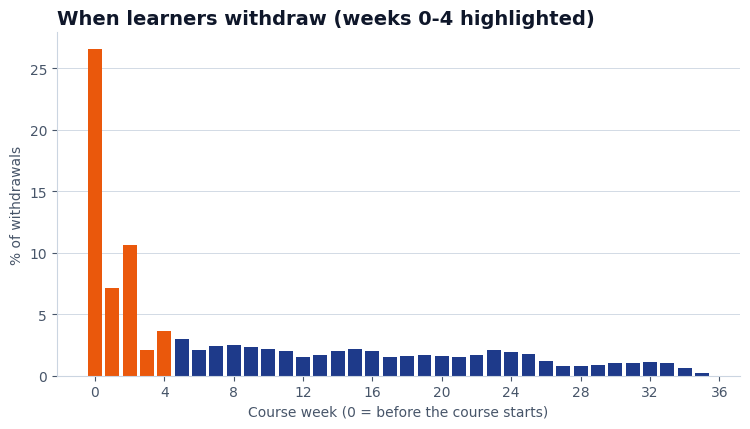

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Learners who withdrew, with a recorded unregistration date
w = base[base["dropout"] == 1].copy()
print("Withdrawn learners:", len(w))
print("With a recorded unregistration date:", w["date_unregistration"].notna().sum())
w = w.dropna(subset=["date_unregistration"])

# Week of withdrawal (week 0 = before the course starts; days 0-6 = week 1, ...)
w["week"] = (w["date_unregistration"] // 7 + 1).clip(lower=0).astype(int)

by_week = w["week"].value_counts().sort_index()
share = (by_week / len(w) * 100).round(1)
table = pd.DataFrame({"withdrawals": by_week, "share_%": share,
                      "cumulative_%": share.cumsum().round(1)})
print(table.head(15))

# Chart: weeks 0-4 in terracotta (half of all withdrawals), later weeks in navy
plot_share = share.loc[:36]
colors = [TERRA if k <= 4 else NAVY for k in plot_share.index]

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.bar(plot_share.index, plot_share.values, width=0.8, color=colors)
style(ax, "When learners withdraw (weeks 0-4 highlighted)",
      "Course week (0 = before the course starts)", "% of withdrawals")
ax.set_xticks(range(0, 37, 4))
plt.tight_layout()
fig.savefig(os.path.join(path, "chart_timing.png"), dpi=200)
plt.show()

In [16]:
# Share of ALL learner-module records that had unregistered by each day
for d in [0, 28, 60, 120, 180]:
    n = (base["date_unregistration"] <= d).sum()
    print(f"Unregistered by day {d:>3}: {n:>6}  ({n / len(base) * 100:.1f}% of all learners)")

# Median day of withdrawal, by module
print(w.groupby("code_module")["date_unregistration"]
        .agg(withdrawals="size", median_day="median").round(0))

Unregistered by day   0:   3097  (9.5% of all learners)
Unregistered by day  28:   5055  (15.5% of all learners)
Unregistered by day  60:   6232  (19.1% of all learners)
Unregistered by day 120:   7816  (24.0% of all learners)
Unregistered by day 180:   9318  (28.6% of all learners)
             withdrawals  median_day
code_module                         
AAA                  126       116.0
BBB                 2374        12.0
CCC                 1947        32.0
DDD                 2232        46.0
EEE                  718        16.0
FFF                 2377        31.0
GGG                  289        73.0


                   learners  % of all
Registered            32593     100.0
After day 0           29496      90.5
After day 28          27538      84.5
After day 60          26361      80.9
After day 120         24777      76.0
After day 180         23275      71.4
Stayed to the end     22437      68.8


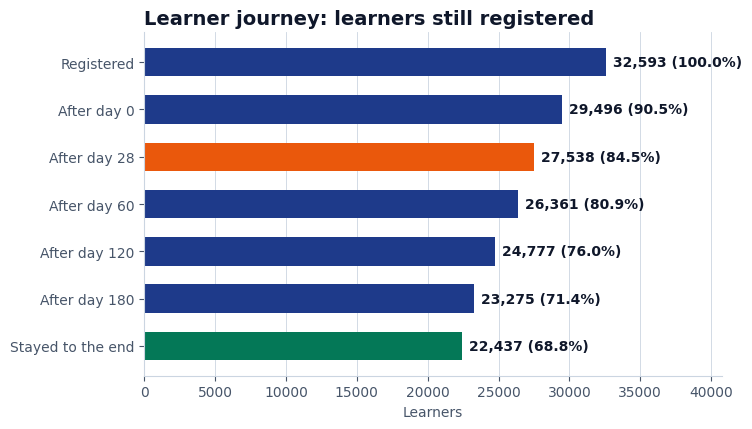

In [17]:
stages = {"Registered": len(base)}
for d in [0, 28, 60, 120, 180]:
    stages[f"After day {d}"] = len(base) - (base["date_unregistration"] <= d).sum()
stages["Stayed to the end"] = (base["dropout"] == 0).sum()

funnel = pd.Series(stages)
pct = (funnel / len(base) * 100).round(1)
print(pd.DataFrame({"learners": funnel, "% of all": pct}))

# Colours: day 28 = terracotta (the key cut-off), stayed to the end = emerald, the rest navy
colors = [NAVY] * len(funnel)
colors[2] = TERRA
colors[-1] = EMER

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.barh(funnel.index, funnel.values, color=colors, height=0.6)
ax.invert_yaxis()
ax.set_title("Learner journey: learners still registered", loc="left")
ax.set_xlabel("Learners")
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.set_xlim(0, funnel.max() * 1.25)
for i, (v, p) in enumerate(zip(funnel.values, pct.values)):
    ax.text(v + funnel.max() * 0.015, i, f"{v:,} ({p}%)", va="center", fontweight="bold", fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join(path, "chart_funnel.png"), dpi=200)
plt.show()

In [18]:
late = base[(base["dropout"] == 1) & ((base["date_unregistration"] > 180) | base["date_unregistration"].isna())]
print("Withdrawn after day 180 or with no date:", len(late))
print("  of which no date recorded:", late["date_unregistration"].isna().sum())

Withdrawn after day 180 or with no date: 847
  of which no date recorded: 93


**Finding:** Of 10,063 withdrawals with a recorded date, 26.6% happened before the course start and 50.0% by the end of week 4(day 28), so the first month is the main drop-off point. Withdrawals continue at about 2% per week afterwards. Timing differs by module: the median withdrawal day is 12 in BBB and 16 in EEE, but 46 in DDD and 73 in GGG. A week-4 flag can only reach learners still registered at that point, around half of all withdrawals, so earlier outreach (before the course and in the first weeks) is needed alongside it.

In [19]:
odd = base[(base["date_unregistration"] <= 180) & (base["dropout"] == 0)]
print("Unregistered by day 180 but not labelled Withdrawn:", len(odd))
print(odd["final_result"].value_counts())

Unregistered by day 180 but not labelled Withdrawn: 9
final_result
Fail    9
Name: count, dtype: int64


847 learners labelled Withdrawn left after day 180 or have no recorded unregistration date (93 have no date, 754 withdrew after day 180). This accounts for most of the drop in the last step of the funnel. A further 9 learners have an unregistration date by day 180 but a final result of Fail, not Withdrawn, which explains the small difference between the funnel (838) and this count (847). They are counted as retained in the dropout definition, since they have a final result.

**Objective 3: Identify early signals of dropout.** The early-warning analysis is built on learners still registered at week 4 (day 28), since only they can still be warned. This section tests which early signals (clicks, days active, and a missed due assessment) are linked to later withdrawal.

In [20]:
# Keep learners who had not unregistered by day 28
at_week4 = base[(base["date_unregistration"].isna()) | (base["date_unregistration"] > 28)].copy()

print("All learners:", len(base))
print("Still registered at week 4:", len(at_week4))
print("Removed (left before week 4):", len(base) - len(at_week4))
print("Dropout rate among learners still registered at week 4:",
      round(at_week4["dropout"].mean() * 100, 1), "%")

All learners: 32593
Still registered at week 4: 27538
Removed (left before week 4): 5055
Dropout rate among learners still registered at week 4: 18.6 %


**studentVle** records each student’s daily clicks on the online learning platform (about 10.6 million rows). To fit in memory, only the five columns needed for this analysis are loaded, using compact data types.

In [21]:
student_vle = pd.read_csv(
    os.path.join(path, "studentVle.csv"),
    usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
    dtype={"code_module": "category", "code_presentation": "category",
           "id_student": "int32", "date": "int16", "sum_click": "int16"}
)
print(student_vle.shape)
student_vle.head()

(10655280, 5)


,code_module,code_presentation,id_student,date,sum_click
0,AAA,2013J,28400,-10,4
1,AAA,2013J,28400,-10,1
2,AAA,2013J,28400,-10,1
3,AAA,2013J,28400,-10,11
4,AAA,2013J,28400,-10,1


**Weekly clicks per student.** The daily click data is summed into weekly totals per learner. date is the day relative to the course start, so days 0-6 are week 1, days 7-13 are week 2, and so on. Clicks before day 0 (pre-course activity) are excluded.

In [22]:
# Keeping only clicks from day 0 onwards (the course start)
clicks = student_vle[student_vle["date"] >= 0].copy()

# Convert the day number into a week number (days 0-6 = week 1, 7-13 = week 2, ...)
clicks["week"] = clicks["date"] // 7 + 1

# Add up clicks per student, per module, per week
weekly = (clicks.groupby(keys + ["week"], observed=True)["sum_click"]
                .sum()
                .reset_index())

print(weekly.shape)
weekly.head()

(579438, 5)


,code_module,code_presentation,id_student,week,sum_click
0,AAA,2013J,11391,1,183
1,AAA,2013J,11391,2,20
2,AAA,2013J,11391,3,100
3,AAA,2013J,11391,5,26
4,AAA,2013J,11391,6,60


In [23]:
# The weekly table is saved to Drive as a small, reusable file
weekly.to_csv(os.path.join(path, "weekly_clicks.csv"), index=False)

In [24]:
keys = ["code_module", "code_presentation", "id_student"]

**Early engagement (weeks 1-4).** Each learner’s clicks in the first four weeks are added up. Learners with no recorded clicks get 0. Engagement will be compared between learners who withdrew later and those who stayed.

In [25]:
# Total clicks per learner in weeks 1-4
early = (weekly[weekly["week"] <= 4]
         .groupby(keys, observed=True)["sum_click"]
         .sum()
         .reset_index(name="clicks_w1_4"))

# Attach to the learners still registered at week 4
df = at_week4.merge(early, on=keys, how="left")

# Learners with no click records get 0
df["clicks_w1_4"] = df["clicks_w1_4"].fillna(0)

print(df.shape)

(27538, 17)


In [26]:
# compare the two groups
# 0 = retained, 1 = dropout
df.groupby("dropout")["clicks_w1_4"].describe()

,count,mean,std,min,25%,50%,75%,max
dropout,,,,,,,,
0,22429.0,287.845245,340.916229,0.0,70.0,184.0,385.0,6084.0
1,5109.0,224.604619,276.219542,0.0,52.0,141.0,299.0,4114.0


**Dropout rate by engagement level**

In [27]:
# Group learners into engagement bands based on weeks 1-4 clicks
df["engagement_band"] = pd.cut(
    df["clicks_w1_4"],
    bins=[-1, 0, 25, 100, 300, 1_000_000],
    labels=["0 clicks", "1-25", "26-100", "101-300", "300+"]
)

# Learners and dropout rate in each band
print(df.groupby("engagement_band", observed=True)["dropout"]
        .agg(learners="count", dropout_rate="mean")
        .round(3))

                 learners  dropout_rate
engagement_band                        
0 clicks             1246         0.242
1-25                 2432         0.215
26-100               5579         0.206
101-300              9528         0.196
300+                 8753         0.145


**Chart** shows the dropout rate by engagement level in weeks 1-4. Chart 2 shows average weekly clicks for learners who later withdrew compared with those who stayed.

**Average weekly clicks, dropouts vs retained**

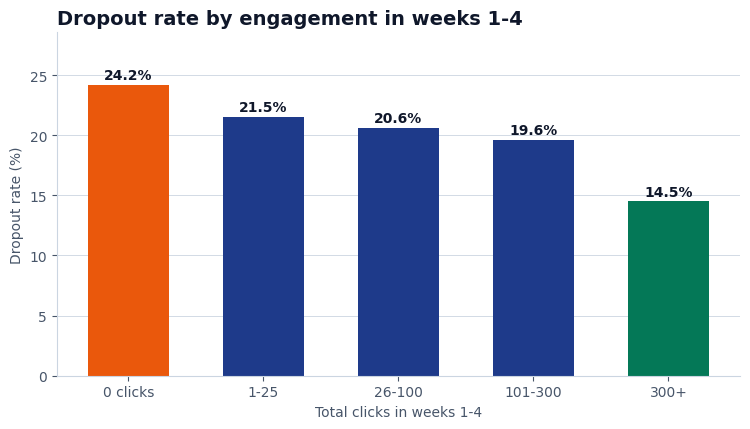

In [28]:
# Dropout rate (%) in each engagement band
band_rates = (df.groupby("engagement_band", observed=True)["dropout"].mean() * 100).round(1)

# No clicks = terracotta (highest dropout), 300+ clicks = emerald (lowest), the rest navy
colors = [TERRA, NAVY, NAVY, NAVY, EMER]

bar(band_rates, "Dropout rate by engagement in weeks 1-4", "Total clicks in weeks 1-4",
    colors=colors, fname="chart_engagement.png")

In [29]:
import inspect
print(inspect.signature(bar))

(series, title, xlabel='', ylabel='Dropout rate (%)', colors=None, fname=None)


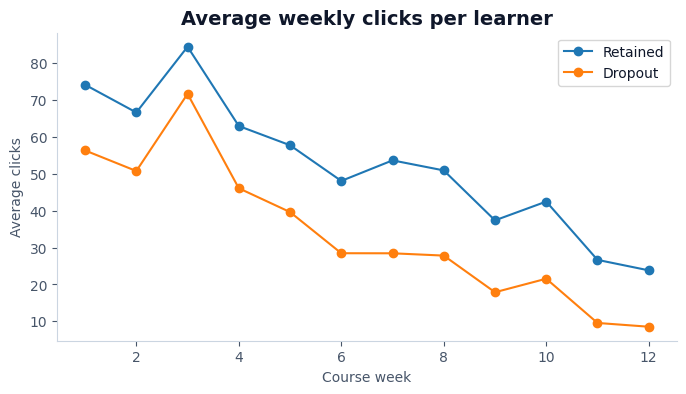

In [30]:
w = weekly.merge(df[keys + ["dropout"]], on=keys, how="inner")

# Total clicks per week for each group, divided by the number of learners in that group
group_size = df.groupby("dropout").size()
avg_clicks = (w.groupby(["week", "dropout"])["sum_click"].sum()
                .unstack()
                .div(group_size, axis=1))

# The first 12 weeks
ax = avg_clicks.loc[1:12].plot(figsize=(8, 4), marker="o")
ax.set_title("Average weekly clicks per learner")
ax.set_xlabel("Course week")
ax.set_ylabel("Average clicks")
ax.legend(["Retained", "Dropout"])
plt.show()

**Second early signal:** assessment submission by week 4. Do learners who submitted at least one assessment by day 28 dropped out less often.

In [31]:
# Link each submission to its module and presentation
sub = student_assess.merge(
    assessments[["id_assessment", "code_module", "code_presentation"]],
    on="id_assessment", how="left"
)

# Count submissions made by day 28
early_sub = (sub[sub["date_submitted"] <= 28]
             .groupby(keys).size()
             .reset_index(name="n_sub_w4"))

df = df.merge(early_sub, on=keys, how="left")
df["n_sub_w4"] = df["n_sub_w4"].fillna(0)
df["submitted_by_w4"] = (df["n_sub_w4"] > 0).astype(int)

# Dropout rate: submitted vs did not submit by week 4
print(df.groupby("submitted_by_w4")["dropout"]
        .agg(learners="count", dropout_rate="mean").round(3))

                 learners  dropout_rate
submitted_by_w4                        
0                    7130         0.210
1                   20408         0.177


In [32]:
# Earliest assessment due date in each module presentation
first_due = (assessments.groupby(["code_module", "code_presentation"])["date"]
                        .min().reset_index(name="first_due_day"))
print(first_due.sort_values("first_due_day"))

   code_module code_presentation  first_due_day
4          BBB             2014B           12.0
6          CCC             2014B           18.0
7          CCC             2014J           18.0
0          AAA             2013J           19.0
3          BBB             2013J           19.0
2          BBB             2013B           19.0
1          AAA             2014J           19.0
5          BBB             2014J           19.0
15         FFF             2013B           19.0
16         FFF             2013J           19.0
11         DDD             2014J           20.0
8          DDD             2013B           23.0
17         FFF             2014B           24.0
18         FFF             2014J           24.0
10         DDD             2014B           25.0
9          DDD             2013J           25.0
14         EEE             2014J           33.0
13         EEE             2014B           33.0
12         EEE             2013J           33.0
19         GGG             2013J        

In [33]:
df = df.merge(first_due, on=["code_module", "code_presentation"], how="left")
due_by_w4 = df[df["first_due_day"] <= 28]

print(due_by_w4.groupby("submitted_by_w4")["dropout"]
               .agg(learners="count", dropout_rate="mean").round(3))

                 learners  dropout_rate
submitted_by_w4                        
0                    2423         0.404
1                   20125         0.179


**Finding:** In course presentations where an assessment was due by day 28, learners who had not submitted withdrew at 40.4%, compared with 17.9% for those who had. In EEE and GGG, no assessment was due by week 4, so this signal is not available there. This is an association: missing a due assessment may be a symptom of disengagement, not the cause.

**Objective 4: Build the at-risk flag.** Combine the early signals into a risk score for each learner at week 4, and report how accurate it is. Model 1 is a logistic regression using five signals: clicks in weeks 1-4, whether an assessment was due by week 4, whether a due assessment was missed, number of previous attempts, and studied credits. Only information available by day 28 is used, to avoid data leakage. The model is trained on 70% of learners and tested on the other 30%. Later steps add more signals and check whether the flag adds value beyond module.

In [34]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Feature 1: was an assessment due by week 4 in this course?
df["due_by_w4"] = (df["first_due_day"] <= 28).astype(int)

# Feature 2: missed an assessment that WAS due by week 4
df["missed_due"] = ((df["due_by_w4"] == 1) & (df["submitted_by_w4"] == 0)).astype(int)

# Feature 3: log of early clicks (reduces the effect of very high click counts)
df["log_clicks"] = np.log1p(df["clicks_w1_4"])

features = ["log_clicks", "missed_due", "due_by_w4",
            "num_of_prev_attempts", "studied_credits"]
X = df[features]
y = df["dropout"]

# 70% training, 30% testing; stratify keeps the dropout share equal in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# class_weight="balanced" makes the model pay more attention to the dropout group
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]
print("AUC:", round(roc_auc_score(y_test, probs), 3))
print(classification_report(y_test, model.predict(X_test),
                            target_names=["Retained", "Dropout"]))

AUC: 0.615
              precision    recall  f1-score   support

    Retained       0.85      0.71      0.78      6729
     Dropout       0.26      0.44      0.33      1533

    accuracy                           0.66      8262
   macro avg       0.55      0.58      0.55      8262
weighted avg       0.74      0.66      0.69      8262



**Finding**: A logistic regression using five early signals (weeks 1-4 clicks, missed due assessment, whether one was due, previous attempts, studied credits) reached an AUC of 0.615 on held-out learners. The flag identified 44% of learners who later withdrew, with 26% precision against a baseline dropout rate of 18.6%. The signals carry real but limited information, so the flag works as a screening aid to prioritise follow-up, not as a reliable predictor of individual outcomes.

**accuracy of the model**

**Model v2:** adding engagement consistency and learner characteristics. All features are known by day 28. Results are compared against the first model.

In [35]:
# Read the big file in chunks and keep only days 0-27 (the first four weeks)
chunks = []
for chunk in pd.read_csv(
        os.path.join(path, "studentVle.csv"),
        usecols=["code_module", "code_presentation", "id_student", "date"],
        dtype={"code_module": "category", "code_presentation": "category",
               "id_student": "int32", "date": "int16"},
        chunksize=1_000_000):
    chunks.append(chunk[(chunk["date"] >= 0) & (chunk["date"] <= 27)])

vle_early = pd.concat(chunks, ignore_index=True)
print(vle_early.shape)

(2112323, 4)


In [36]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Feature: number of different days the learner was active in days 0-27
active = (vle_early
          .groupby(keys, observed=True)["date"].nunique()
          .reset_index(name="days_active_w1_4"))
df = df.merge(active, on=keys, how="left")
df["days_active_w1_4"] = df["days_active_w1_4"].fillna(0)

# Learner characteristics (fill missing deprivation band with "Unknown")
df["imd_band"] = df["imd_band"].fillna("Unknown")
cat_cols = ["code_module", "gender", "region", "highest_education",
            "imd_band", "age_band", "disability"]
num_cols = ["log_clicks", "days_active_w1_4", "missed_due", "due_by_w4",
            "num_of_prev_attempts", "studied_credits"]

X2 = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True)
y = df["dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.3, random_state=42, stratify=y)

# Compare two models on the same split
models = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=42, class_weight="balanced"),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    print(f"\n{name}: AUC = {roc_auc_score(y_test, p):.3f}")
    print(classification_report(y_test, m.predict(X_test),
                                target_names=["Retained", "Dropout"]))


Logistic regression: AUC = 0.688
              precision    recall  f1-score   support

    Retained       0.88      0.68      0.77      6729
     Dropout       0.30      0.60      0.40      1533

    accuracy                           0.67      8262
   macro avg       0.59      0.64      0.59      8262
weighted avg       0.77      0.67      0.70      8262


Gradient boosting: AUC = 0.676
              precision    recall  f1-score   support

    Retained       0.87      0.70      0.78      6729
     Dropout       0.30      0.55      0.39      1533

    accuracy                           0.68      8262
   macro avg       0.59      0.63      0.58      8262
weighted avg       0.77      0.68      0.71      8262



**Finding:** Adding days active in weeks 1-4 and learner characteristics raised the AUC from 0.615 to 0.688. The logistic regression flags 60% of learners who later withdrew, with 30% precision against an 18.6% baseline. Gradient boosting (AUC 0.676) gave no meaningful gain, so the simpler, more explainable logistic regression is used. The flag is a screening aid for prioritising follow-up, not a reliable predictor of individual outcomes.

**Risk scores and bands.** Each learner's dropout risk at week 4 is estimated with 5-fold cross-validation with shuffled folds, so every score comes from a model that did not see that learner. Learners are grouped into High (top 20%), Medium (next 30%), and Low (bottom 50%) risk, and the actual dropout rate is checked in each band.

In [37]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

# Shuffled folds: the data is sorted by module, so unshuffled folds break the model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Out-of-sample risk score for every learner (each score comes from a model that never saw that learner)
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
df["risk_score"] = cross_val_predict(lr, X2, y, cv=cv, method="predict_proba")[:, 1]

print("Full model AUC:", round(roc_auc_score(y, df["risk_score"]), 3))

# Risk bands: top 20% = High, next 30% = Medium, bottom 50% = Low
df["risk_band"] = pd.qcut(df["risk_score"].rank(method="first"),
                          q=[0, 0.5, 0.8, 1.0],
                          labels=["Low", "Medium", "High"])

# Do the bands really separate dropout rates?
print(df.groupby("risk_band", observed=True)["dropout"]
        .agg(learners="count", dropout_rate="mean").round(3))

Full model AUC: 0.686
           learners  dropout_rate
risk_band                        
Low           13769         0.107
Medium         8261         0.203
High           5508         0.357


**Finding:** Using 5-fold cross-validation with shuffled folds (AUC 0.686), learners were grouped by predicted dropout risk at week 4. Dropout rose clearly across the bands: 10.7% (Low, bottom 50%), 20.3% (Medium, next 30%), and 35.7% (High, top 20%). The High band withdrew at about twice the average rate (18.6%), so the flag can prioritise follow-up. It is a screening aid and does not predict individual outcomes with certainty.

**Which signals matter most.** Positive values raise predicted dropout risk and negative values lower it. Numeric features are on different scales, so compare signs and rough size only. Categorical features are compared with a dropped reference group (for example, module AAA).

In [38]:
lr.fit(X2, y)
coefs = pd.Series(lr.coef_[0], index=X2.columns).sort_values()
print(coefs.head(8))   # most protective (lower dropout risk)
print(coefs.tail(8))   # strongest risk factors

code_module_GGG    -0.793522
imd_band_Unknown   -0.599111
code_module_BBB    -0.424793
imd_band_90-100%   -0.291684
imd_band_80-90%    -0.270366
imd_band_50-60%    -0.224994
imd_band_70-80%    -0.205492
gender_M           -0.175248
dtype: float64
region_North Region                     0.220394
code_module_FFF                         0.260836
highest_education_Lower Than A Level    0.368121
disability_Y                            0.444641
code_module_DDD                         0.503733
highest_education_No Formal quals       0.605604
missed_due                              0.751986
code_module_CCC                         0.907234
dtype: float64


**Finding:** Missing an assessment that was due by week 4 is the strongest signal a project coordinator can act on, consistent with the 40.4% vs 17.9% gap found earlier. Module effects are also large. Learner background (education level, disability, deprivation band) contributes, but these are associations, not causes, and background factors should be used to monitor equity, not to decide who receives support.

In [39]:
# Dropout rate by risk decile (1 = lowest risk, 10 = highest)
df["decile"] = pd.qcut(df["risk_score"].rank(method="first"), 10, labels=range(1, 11))
print(df.groupby("decile", observed=True)["dropout"].mean().round(3))

decile
1     0.073
2     0.081
3     0.108
4     0.131
5     0.139
6     0.160
7     0.210
8     0.239
9     0.286
10    0.427
Name: dropout, dtype: float64


**Finding:** Dropout rises steadily with predicted risk, from 7.3% in the lowest-risk decile to 42.7% in the highest. The risk score ranks learners consistently across the whole range, not only at the top.

In [40]:
# Module mix in each decile (share of learners per module)
print(pd.crosstab(df["decile"], df["code_module"], normalize="index").round(2))

code_module   AAA   BBB   CCC   DDD   EEE   FFF   GGG
decile                                               
1            0.03  0.28  0.00  0.01  0.11  0.09  0.49
2            0.04  0.35  0.00  0.04  0.15  0.19  0.22
3            0.05  0.39  0.00  0.08  0.16  0.23  0.09
4            0.04  0.34  0.02  0.13  0.15  0.28  0.05
5            0.03  0.29  0.03  0.18  0.13  0.32  0.02
6            0.02  0.23  0.07  0.26  0.09  0.32  0.01
7            0.02  0.16  0.14  0.31  0.08  0.30  0.00
8            0.01  0.12  0.27  0.30  0.04  0.26  0.00
9            0.01  0.12  0.36  0.29  0.02  0.19  0.00
10           0.01  0.07  0.38  0.32  0.00  0.21  0.00


**Observation:** Module shapes the ranking but does not fully explain it. Module GGG makes up 49% of the lowest-risk decile, while CCC (38%) and DDD (32%) dominate the highest. Dropout rises steadily across deciles, from 7.3% in decile 1 to 42.7% in decile 10.

**Is the flag just a module effect? Compares the full model with a module-only model, and checks the High tier within each module.**

In [41]:
# Who is in the High tier, and how each module does
# Module mix of the High tier
print(df[df["risk_band"] == "High"]["code_module"].value_counts(normalize=True).round(2))

# Learners and dropout rate by module, Low / Medium / High
print(df.pivot_table(index="code_module", columns="risk_band", observed=True,
                     values="dropout", aggfunc=["count", "mean"]).round(3))

code_module
CCC    0.37
DDD    0.31
FFF    0.20
BBB    0.10
EEE    0.01
AAA    0.01
Name: proportion, dtype: float64
              count                   mean              
risk_band       Low  Medium    High    Low Medium   High
code_module                                             
AAA           527.0   138.0    53.0  0.123  0.130  0.245
BBB          4518.0  1380.0   536.0  0.113  0.187  0.274
CCC           147.0  1313.0  2059.0  0.143  0.219  0.365
DDD          1199.0  2393.0  1692.0  0.115  0.206  0.375
EEE          1903.0   593.0    57.0  0.099  0.226  0.316
FFF          3072.0  2410.0  1111.0  0.116  0.198  0.362
GGG          2403.0    34.0     NaN  0.078  0.235    NaN


**Finding**: Within most modules, dropout rises from the Low to the High risk band (for example, DDD 11.5%, 20.6%, 37.5%; BBB 11.3%, 18.7%, 27.4%), so the flag adds information beyond module membership. The High band is concentrated in CCC, DDD, and FFF, and GGG has no High-band learners, which is why a within-module flag is also provided. Several module-band groups are small (for example AAA, EEE, and GGG), so their rates should be read with caution

In [42]:
# Does the full model beat a module-only model? (same shuffled folds as the full model)
mod_X = pd.get_dummies(df[["code_module"]], drop_first=True)
mod_p = cross_val_predict(LogisticRegression(max_iter=1000), mod_X, y,
                          cv=cv, method="predict_proba")[:, 1]
print("Module-only AUC:", round(roc_auc_score(y, mod_p), 3))
print("Full model AUC: ", round(roc_auc_score(y, df["risk_score"]), 3))

Module-only AUC: 0.613
Full model AUC:  0.686


**Finding:** A module-only model reaches an AUC of 0.613, compared with 0.686 for the full model. The early engagement, assessment, and background signals therefore add value beyond module membership, although module alone is already informative.

In [43]:
# Flag the top 20% within each module
df["risk_pct_in_module"] = df.groupby("code_module")["risk_score"].rank(pct=True)
df["risk_band_in_module"] = np.where(df["risk_pct_in_module"] >= 0.8, "High", "Standard")

print(df.groupby("risk_band_in_module")["dropout"]
        .agg(learners="count", dropout_rate="mean").round(3))
print(df.pivot_table(index="code_module", columns="risk_band_in_module",
                     values="dropout", aggfunc="mean").round(3))

                     learners  dropout_rate
risk_band_in_module                        
High                     5510         0.323
Standard                22028         0.151
risk_band_in_module   High  Standard
code_module                         
AAA                  0.188     0.120
BBB                  0.239     0.118
CCC                  0.490     0.254
DDD                  0.434     0.191
EEE                  0.249     0.105
FFF                  0.345     0.148
GGG                  0.115     0.071


In [44]:
export_cols = keys + ["gender", "region", "age_band", "highest_education", "imd_band",
                      "clicks_w1_4", "days_active_w1_4", "submitted_by_w4",
                      "missed_due", "risk_score", "risk_band", "risk_band_in_module",
                      "decile", "dropout"]
df[export_cols].to_csv(os.path.join(path, "learner_risk_scores.csv"), index=False)
print("Saved:", df[export_cols].shape)

Saved: (27538, 17)


In [45]:
import matplotlib.pyplot as plt

BLUE = "#2a78d6"

def bar(series, title, xlabel="", ylabel="Dropout rate (%)", color=BLUE, figsize=(7, 4)):
    ax = series.plot(kind="bar", color=color, figsize=figsize)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=0)
    for i, v in enumerate(series):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
    plt.tight_layout()
    plt.show()

**Objective 1** Dropout by module (all learners)

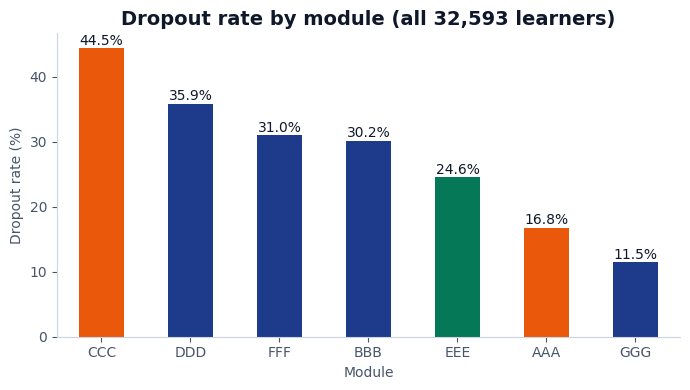

In [46]:
mod = (base.groupby("code_module")["dropout"].mean() * 100).round(1).sort_values(ascending=False)

# Highest = terracotta, lowest = emerald, the rest navy (the sort order must stay as it is)
color = [TERRA] + [NAVY] * (len(mod) - 2) + [EMER]

bar(mod, "Dropout rate by module (all 32,593 learners)", "Module",
    color=colors)

**Objective 3** The missed assessment gap

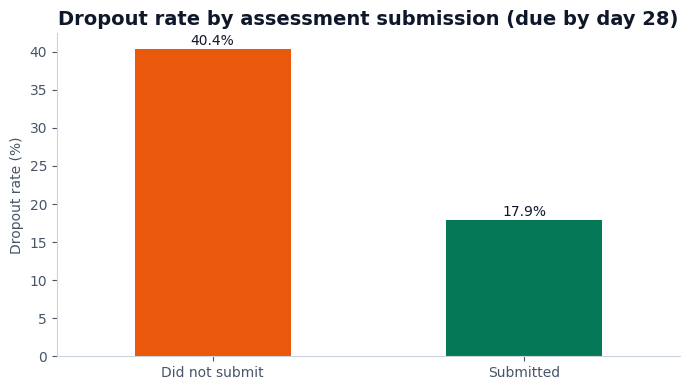

In [47]:
# Only courses where an assessment was due by day 28
due = df[df["first_due_day"] <= 28]
gap = (due.groupby("submitted_by_w4")["dropout"].mean() * 100).round(1)
gap.index = ["Did not submit", "Submitted"]

bar(gap, "Dropout rate by assessment submission (due by day 28)",
    color=[TERRA, EMER])

**Objective 4** Dropout by risk band

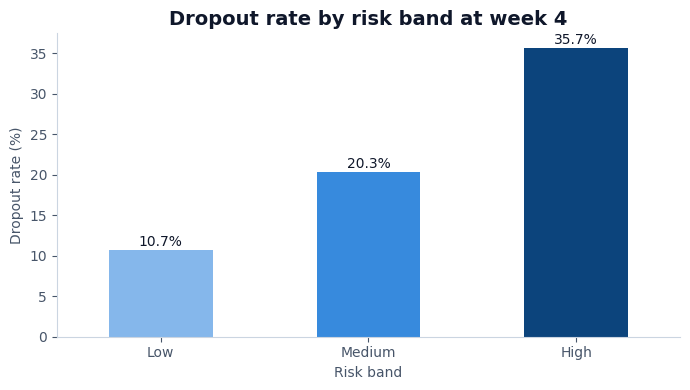

In [48]:
order = ["Low", "Medium", "High"]
rb = (df.groupby("risk_band", observed=True)["dropout"].mean() * 100).round(1).reindex(order)
bar(rb, "Dropout rate by risk band at week 4", "Risk band",
    color=["#85b7eb", "#378add", "#0c447c"])

**The decile line**

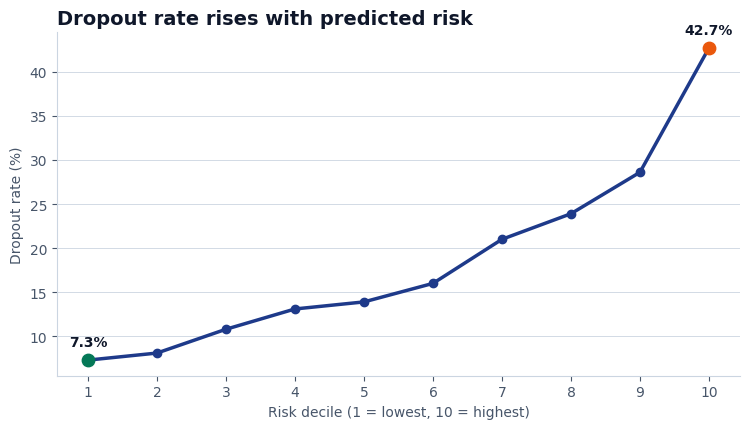

In [49]:
dec = (df.groupby("decile", observed=True)["dropout"].mean() * 100).round(1)
x = list(range(1, 11))

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.plot(x, dec.values, color=NAVY, marker="o", linewidth=2.5)
ax.scatter([1], [dec.values[0]], color=EMER, s=80, zorder=3)
ax.scatter([10], [dec.values[-1]], color=TERRA, s=80, zorder=3)
ax.annotate(f"{dec.values[0]}%", (1, dec.values[0]), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")
ax.annotate(f"{dec.values[-1]}%", (10, dec.values[-1]), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")
ax.set_xticks(x)
style(ax, "Dropout rate rises with predicted risk", "Risk decile (1 = lowest, 10 = highest)", "Dropout rate (%)")
plt.tight_layout()
fig.savefig(os.path.join(path, "chart_deciles.png"), dpi=200)
plt.show()

**The action list, the part a project coordinator would use**

In [51]:
import ipywidgets as widgets
from IPython.display import display

def show(module):
    sub = df[df["risk_band"] == "High"]
    if module != "All":
        sub = sub[sub["code_module"] == module]
    display(sub.sort_values("risk_score", ascending=False)
               [["id_student", "code_module", "risk_score", "clicks_w1_4", "missed_due"]]
               .head(15).round(3))

widgets.interact(show, module=["All"] + sorted(df["code_module"].unique()))

interactive(children=(Dropdown(description='module', options=('All', 'AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF',…

<function __main__.show(module)>

## Summary of findings

**Objective 1: What are the baseline dropout and pass rates, and which groups are affected most?**
Of 32,593 learner-module records, 31.2% withdrew and 47.2% passed. Dropout varies most by module (CCC 44.5% to GGG 11.5%), then by prior education (42.9% for no formal qualifications to 23.6% for postgraduates) and region (35.6% in the North Western Region to 23.1% in Ireland). Gender differences are small (31.7% male, 30.5% female).

**Objective 2: At what points in the course do learners withdraw?**
Mainly in the first month. Of 10,063 withdrawals with a recorded date, 26.6% happened before the course start and 50.0% by the end of week 4 (day 28). The median withdrawal day is 12 in BBB and 16 in EEE, but 46 in DDD and 73 in GGG.

**Objective 3: Which early signals are linked to later withdrawal?**
Learners with no clicks in weeks 1-4 withdrew at 24.2%, against 14.5% for those with 300+ clicks. Where an assessment was due by day 28, learners who had not submitted withdrew at 40.4%, against 17.9% for those who had.

**Objective 4: Can the signals be combined into a risk flag, and how accurate is it?**
Yes, with modest accuracy. A logistic regression using only information available by day 28 reached an AUC of 0.686 and flags 60% of later withdrawals at 30% precision (baseline dropout 18.6%). It splits learners into Low (10.7% dropout), Medium (20.3%), and High (35.7%) risk. It adds value beyond module alone (module-only AUC 0.613).

**Objective 5: How can the findings be presented so a project coordinator knows who to contact first?**
Charts show where dropout is highest and which signals matter. A ranked list of High-risk learners, filterable by module, shows who to contact first.

## Limitations
- The data is a UK higher-education proxy dataset, not a real training programme.
- The findings show associations, not causes.
- A week-4 flag can only reach learners still registered at that point. About half of all withdrawals happen earlier.
- Some groups are small, so their rates should be read with caution.
- 93 withdrawals have no recorded unregistration date.
- The flag is a screening aid and does not predict individual outcomes with certainty.
- Learner background is used to monitor equity, not to decide who receives support.